Loaded Tx rows: 2612
Loaded Rx rows: 2612
Loaded Drop rows: 1392

True Packet Delivery Ratio (PDR): 65.23%
Overall Mean End-to-End Delay: 0.0101 seconds
Overall Mean Jitter: 0.0069 seconds

Mean Delay by Priority:
 QoS_Tag
CP    0.010513
OP    0.004560
RP    0.010044
Name: E2EDelay_s, dtype: float64

Application Goodput: 18446.96 bps
MAC Layer Throughput: 18566.96 bps



/tmp/ipykernel_24930/461221332.py:68: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_rx, x='QoS_Tag', y='E2EDelay_s', order=['CP', 'RP', 'OP'], palette='Set2')


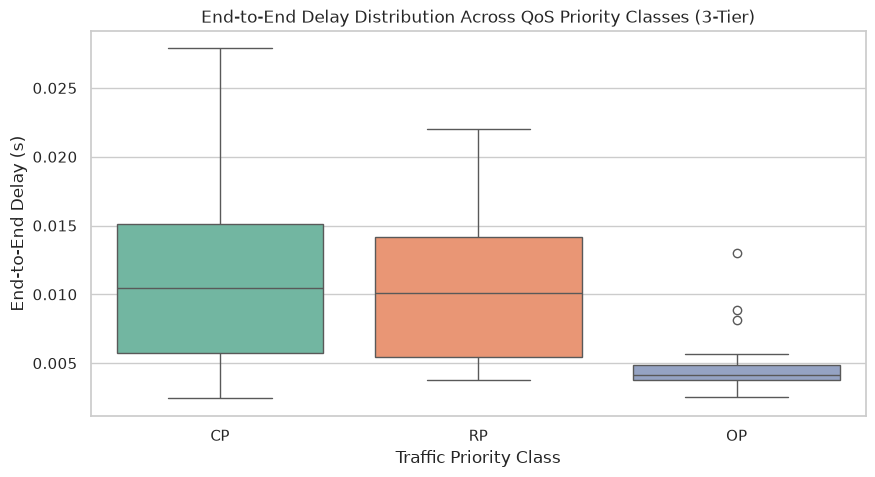

--- DROP ANALYSIS ---


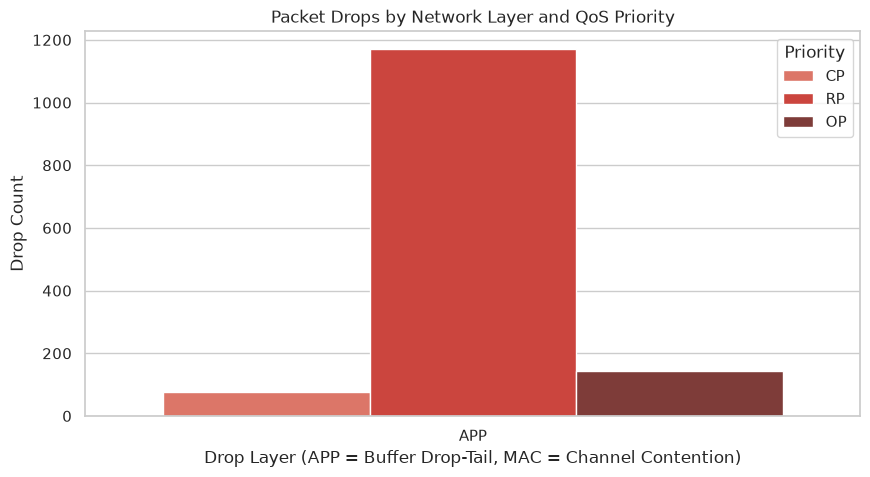

,NodeID,Layer,QoS_Tag,Drop_Count
0,2,APP,CP,7
1,2,APP,OP,5
2,2,APP,RP,30
3,3,APP,CP,32
4,3,APP,OP,52
5,3,APP,RP,447
6,5,APP,OP,2
7,5,APP,RP,13
8,8,APP,CP,4
9,8,APP,OP,2


--- PER-NODE PERFORMANCE TABLE ---


,NodeID,SensorName,SensorType,Total_Generated,Tx_Packets,Dropped_Packets,Rx_Packets,PDR_%,Mean_Delay_s,Mean_Jitter_s
0,2,EEG,Streaming (P0),642.0,600,42.0,600,93.457944,0.010435,0.007338
1,3,HearingAid,Streaming (P0),1125.0,594,531.0,594,52.800000,0.010427,0.007353
2,4,Temperature,Routine (P2),4.0,4,0.0,4,100.000000,0.003682,0.000741
3,5,ECG,Streaming (P0),612.0,597,15.0,597,97.549020,0.011191,0.007289
4,6,BloodPressure,High Event (P1),2.0,2,0.0,2,100.000000,0.003237,0.001605
5,7,InsulinPump,High Event (P1),2.0,2,0.0,2,100.000000,0.003359,0.000313
6,8,SpO2,High Event (P1),391.0,362,29.0,362,92.583120,0.007661,0.005301
7,9,Accelerometer,Routine (P2),19.0,19,0.0,19,100.000000,0.004227,0.000528
8,10,EMG,Streaming (P0),1177.0,402,775.0,402,34.154630,0.010455,0.006978
9,11,MotionSensor,Routine (P2),30.0,30,0.0,30,100.000000,0.004272,0.000855



--- PERFORMANCE BY TRAFFIC HIERARCHY TYPE ---


,SensorType,Total_Generated,Tx_Packets,Dropped_Packets,Rx_Packets,PDR_%,Mean_Delay_s,Mean_Jitter_s
0,High Event (P1),395.0,366,29.0,366,92.658228,0.004752,0.002406
1,Routine (P2),53.0,53,0.0,53,100.000000,0.004060,0.000708
2,Streaming (P0),3556.0,2193,1363.0,2193,61.670416,0.010627,0.007239


/tmp/ipykernel_24930/461221332.py:151: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=node_perf, x='SensorName', y='Mean_Delay_s', ax=ax1, palette='Blues_d', alpha=0.8)


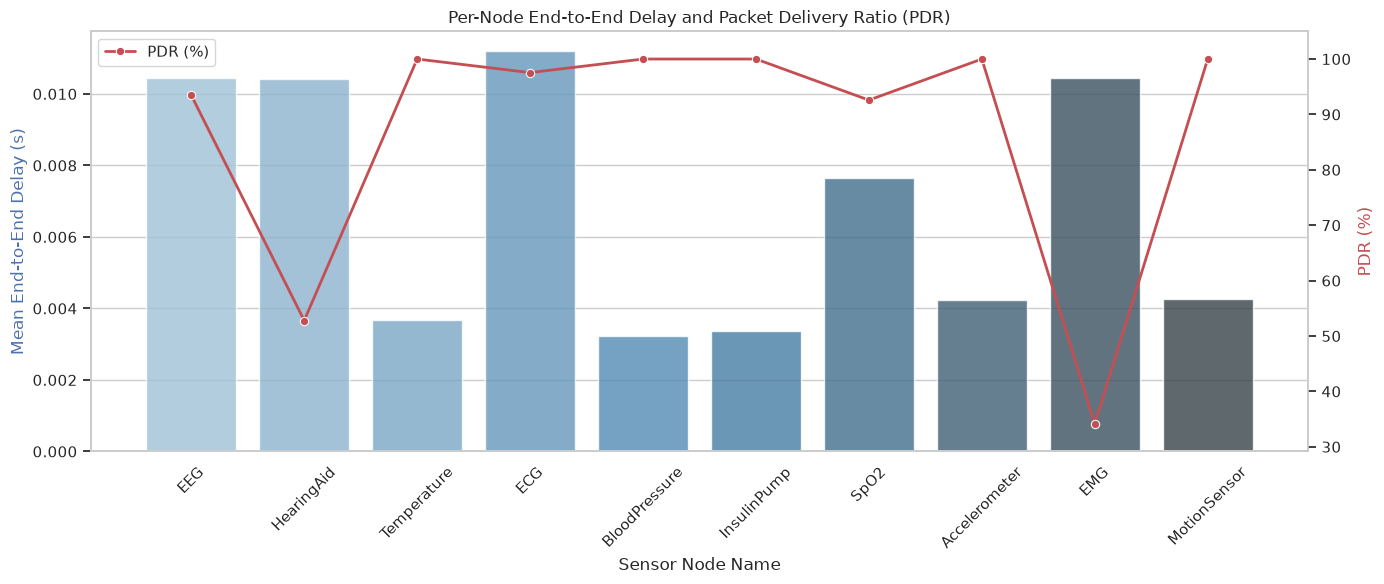

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Configure visualization defaults
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

data_dir = Path('../data')

# Load Datasets
df_tx = pd.read_csv(data_dir / "wban_sim_tx.csv")
df_rx = pd.read_csv(data_dir / "wban_sim_lpu_rx.csv")
df_hub = pd.read_csv(data_dir / "wban_sim_hub.csv")
df_drops = pd.read_csv(data_dir / "wban_sim_drops.csv")

print(f"Loaded Tx rows: {len(df_tx)}")
print(f"Loaded Rx rows: {len(df_rx)}")
print(f"Loaded Drop rows: {len(df_drops)}\n")

# Map priority integers to human-readable QoS tags (3-tier)
prio_map = {0: 'CP', 1: 'RP', 2: 'OP'}
for df in [df_tx, df_rx, df_drops, df_hub]:
    if 'Priority' in df.columns:
        df['QoS_Tag'] = df['Priority'].map(prio_map)

df_rx = df_rx.sort_values(by=['NodeID', 'Time_s'])

# =============================================================================
# 1. OVERALL NETWORK METRICS (CORRECTED PDR)
# =============================================================================
total_generated = len(df_tx) + len(df_drops)
total_rx = len(df_rx)
pdr = (total_rx / total_generated) * 100 if total_generated > 0 else 0

mean_delay = df_rx['E2EDelay_s'].mean()
delay_by_prio = df_rx.groupby('QoS_Tag')['E2EDelay_s'].mean()

df_rx['Jitter_s'] = df_rx.groupby('NodeID')['E2EDelay_s'].diff().abs()
mean_jitter = df_rx['Jitter_s'].mean()

print(f"True Packet Delivery Ratio (PDR): {pdr:.2f}%")
print(f"Overall Mean End-to-End Delay: {mean_delay:.4f} seconds")
print(f"Overall Mean Jitter: {mean_jitter:.4f} seconds")
print("\nMean Delay by Priority:\n", delay_by_prio)

# =============================================================================
# 2. DATA RATES
# =============================================================================
sim_duration = 100.0 

rx_bytes = df_rx['Size_bytes'].sum()
goodput_bps = (rx_bytes * 8) / sim_duration

hub_mac_rx = df_hub[df_hub['Event'] == 'Rx_802.15.4']
mac_bytes = hub_mac_rx['Size_bytes'].sum()
throughput_bps = (mac_bytes * 8) / sim_duration

print(f"\nApplication Goodput: {goodput_bps:.2f} bps")
print(f"MAC Layer Throughput: {throughput_bps:.2f} bps\n")

# =============================================================================
# 3. GLOBAL VISUALIZATIONS & DROP ANALYSIS
# =============================================================================
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_rx, x='QoS_Tag', y='E2EDelay_s', order=['CP', 'RP', 'OP'], palette='Set2')
plt.title('End-to-End Delay Distribution Across QoS Priority Classes (3-Tier)')
plt.xlabel('Traffic Priority Class')
plt.ylabel('End-to-End Delay (s)')
plt.show()

print("--- DROP ANALYSIS ---")
if not df_drops.empty:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df_drops, x='Layer', hue='QoS_Tag', hue_order=['CP', 'RP', 'OP'], palette='Reds_d')
    plt.title('Packet Drops by Network Layer and QoS Priority')
    plt.xlabel('Drop Layer (APP = Buffer Drop-Tail, MAC = Channel Contention)')
    plt.ylabel('Drop Count')
    plt.legend(title='Priority')
    plt.show()
    
    drop_summary = df_drops.groupby(['NodeID', 'Layer', 'QoS_Tag']).size().reset_index(name='Drop_Count')
    display(drop_summary)
else:
    print("No drops recorded in this simulation run.\n")

# =============================================================================
# 4. PER-NODE AGGREGATION & PERFORMANCE (CORRECTED PDR)
# =============================================================================
node_metadata = {
    2: {"SensorName": "EEG", "SensorType": "Streaming (P0)"},
    3: {"SensorName": "HearingAid", "SensorType": "Streaming (P0)"},
    5: {"SensorName": "ECG", "SensorType": "Streaming (P0)"},
    10: {"SensorName": "EMG", "SensorType": "Streaming (P0)"},
    6: {"SensorName": "BloodPressure", "SensorType": "High Event (P1)"},
    7: {"SensorName": "InsulinPump", "SensorType": "High Event (P1)"},
    8: {"SensorName": "SpO2", "SensorType": "High Event (P1)"},
    4: {"SensorName": "Temperature", "SensorType": "Routine (P2)"},
    9: {"SensorName": "Accelerometer", "SensorType": "Routine (P2)"},
    11: {"SensorName": "MotionSensor", "SensorType": "Routine (P2)"}
}

tx_node = df_tx.groupby('NodeID').size().reset_index(name='Tx_Packets')
rx_node = df_rx.groupby('NodeID').size().reset_index(name='Rx_Packets')
node_perf = pd.merge(tx_node, rx_node, on='NodeID', how='outer').fillna(0)

if not df_drops.empty:
    drop_node = df_drops.groupby('NodeID').size().reset_index(name='Dropped_Packets')
    node_perf = pd.merge(node_perf, drop_node, on='NodeID', how='left').fillna(0)
else:
    node_perf['Dropped_Packets'] = 0

# Fix: Denominator is now total packets generated (Tx + Dropped), not just Tx
node_perf['Total_Generated'] = node_perf['Tx_Packets'] + node_perf['Dropped_Packets']
node_perf['PDR_%'] = (node_perf['Rx_Packets'] / node_perf['Total_Generated']) * 100

mean_delay_node = df_rx.groupby('NodeID')['E2EDelay_s'].mean().reset_index(name='Mean_Delay_s')
mean_jitter_node = df_rx.groupby('NodeID')['Jitter_s'].mean().reset_index(name='Mean_Jitter_s')

node_perf = node_perf.merge(mean_delay_node, on='NodeID', how='left').merge(mean_jitter_node, on='NodeID', how='left')
node_perf['SensorName'] = node_perf['NodeID'].map(lambda x: node_metadata.get(x, {}).get('SensorName', 'Unknown'))
node_perf['SensorType'] = node_perf['NodeID'].map(lambda x: node_metadata.get(x, {}).get('SensorType', 'Unknown'))

node_perf = node_perf[['NodeID', 'SensorName', 'SensorType', 'Total_Generated', 'Tx_Packets', 'Dropped_Packets', 'Rx_Packets', 'PDR_%', 'Mean_Delay_s', 'Mean_Jitter_s']]
node_perf = node_perf.sort_values(by='NodeID').reset_index(drop=True)

print("--- PER-NODE PERFORMANCE TABLE ---")
display(node_perf)

type_perf = node_perf.groupby('SensorType').agg({
    'Total_Generated': 'sum',
    'Tx_Packets': 'sum',
    'Dropped_Packets': 'sum',
    'Rx_Packets': 'sum',
    'Mean_Delay_s': 'mean',
    'Mean_Jitter_s': 'mean'
}).reset_index()
type_perf['PDR_%'] = (type_perf['Rx_Packets'] / type_perf['Total_Generated']) * 100
type_perf = type_perf[['SensorType', 'Total_Generated', 'Tx_Packets', 'Dropped_Packets', 'Rx_Packets', 'PDR_%', 'Mean_Delay_s', 'Mean_Jitter_s']]

print("\n--- PERFORMANCE BY TRAFFIC HIERARCHY TYPE ---")
display(type_perf)

# =============================================================================
# 5. PER-NODE VISUALIZATION
# =============================================================================
fig, ax1 = plt.subplots(figsize=(14, 6))

sns.barplot(data=node_perf, x='SensorName', y='Mean_Delay_s', ax=ax1, palette='Blues_d', alpha=0.8)
ax1.set_title('Per-Node End-to-End Delay and Packet Delivery Ratio (PDR)')
ax1.set_xlabel('Sensor Node Name')
ax1.set_ylabel('Mean End-to-End Delay (s)', color='b')
ax1.tick_params(axis='x', rotation=45)

ax2 = ax1.twinx()
sns.lineplot(data=node_perf, x='SensorName', y='PDR_%', ax=ax2, color='r', marker='o', linewidth=2, label='PDR (%)')
ax2.set_ylabel('PDR (%)', color='r')

min_pdr = node_perf['PDR_%'].min()
ax2.set_ylim(max(0, min_pdr - 5), 105) 
ax2.grid(False)

plt.tight_layout()
plt.show()